# Explainable Hybrid Stacking Ensemble for Postpartum Anxiety Screening

## Part A — Setup

In [2]:
# Task 1: Import the libraries
import time
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn import metrics

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
# Task 2: Settings
DATA_FILE = "../data/raw/postpartum_depression.csv"
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

TARGET = "Feeling anxious"
SEED = 42
HYBRID = "Hybrid Stack (proposed)"

BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#9aa0a6", "#2e9e6b"
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

In [4]:
# Task 3: Load the dataset
raw = pd.read_csv(DATA_FILE)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (1503, 11)


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


## Part B — Understanding the data

In [5]:
# Task 4: Column types and possible answers
for column in raw.columns[1:]:
    print(f"{column:45s} -> {sorted(raw[column].dropna().unique())}")

Age                                           -> ['25-30', '30-35', '35-40', '40-45', '45-50']
Feeling sad or Tearful                        -> ['No', 'Sometimes', 'Yes']
Irritable towards baby & partner              -> ['No', 'Sometimes', 'Yes']
Trouble sleeping at night                     -> ['No', 'Two or more days a week', 'Yes']
Problems concentrating or making decision     -> ['No', 'Often', 'Yes']
Overeating or loss of appetite                -> ['No', 'Not at all', 'Yes']
Feeling anxious                               -> ['No', 'Yes']
Feeling of guilt                              -> ['Maybe', 'No', 'Yes']
Problems of bonding with baby                 -> ['No', 'Sometimes', 'Yes']
Suicide attempt                               -> ['No', 'Not interested to say', 'Yes']


In [6]:
# Task 5: Missing answers
missing = raw.isna().sum()
print(missing[missing > 0])
print("Total missing cells:", missing.sum())

Irritable towards baby & partner              6
Problems concentrating or making decision    12
Feeling of guilt                              9
dtype: int64
Total missing cells: 27


In [7]:
# Task 6: Repeated answer patterns
answers = raw.drop(columns="Timestamp")
print("All responses           :", len(answers))
print("Unique answer patterns  :", len(answers.drop_duplicates()))
print("Repeated responses      :", answers.duplicated().sum())

All responses           : 1503
Unique answer patterns  : 326
Repeated responses      : 1177


In [8]:
# Task 7: Clean the data
data = answers.fillna("No answer")
FEATURES = [c for c in data.columns if c != TARGET]
print("Features:", FEATURES)

Features: ['Age', 'Feeling sad or Tearful', 'Irritable towards baby & partner', 'Trouble sleeping at night', 'Problems concentrating or making decision', 'Overeating or loss of appetite', 'Feeling of guilt', 'Problems of bonding with baby', 'Suicide attempt']


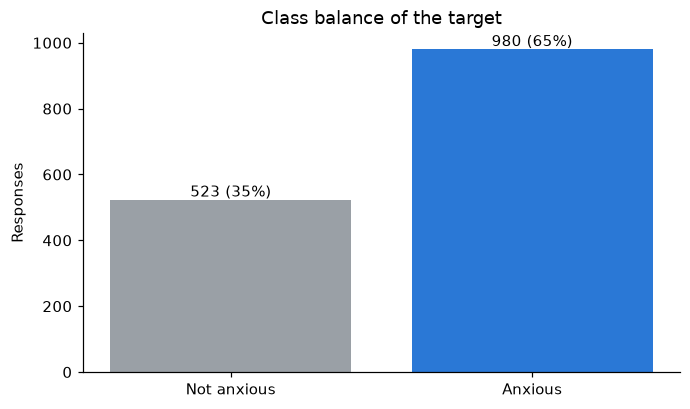

In [9]:
# Task 8: Figure — class balance
counts = data[TARGET].value_counts()
plt.bar(["Not anxious", "Anxious"], [counts["No"], counts["Yes"]], color=[GREY, BLUE])
for i, v in enumerate([counts["No"], counts["Yes"]]):
    plt.text(i, v + 10, f"{v} ({v / len(data):.0%})", ha="center")
plt.ylabel("Responses")
plt.title("Class balance of the target")
plt.savefig(RESULTS / "fig01_class_balance.png")
plt.show()

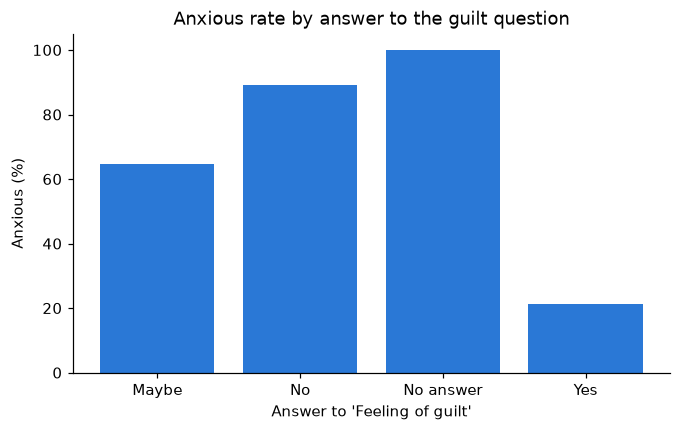

In [10]:
# Task 9: Figure — anxious rate for each answer to one question (guilt)
top_question = "Feeling of guilt"
rate = (data[TARGET] == "Yes").groupby(data[top_question]).mean() * 100
plt.bar(rate.index, rate.values, color=BLUE)
plt.ylabel("Anxious (%)")
plt.xlabel(f"Answer to '{top_question}'")
plt.title("Anxious rate by answer to the guilt question")
plt.savefig(RESULTS / "fig02_anxious_rate_by_guilt.png")
plt.show()

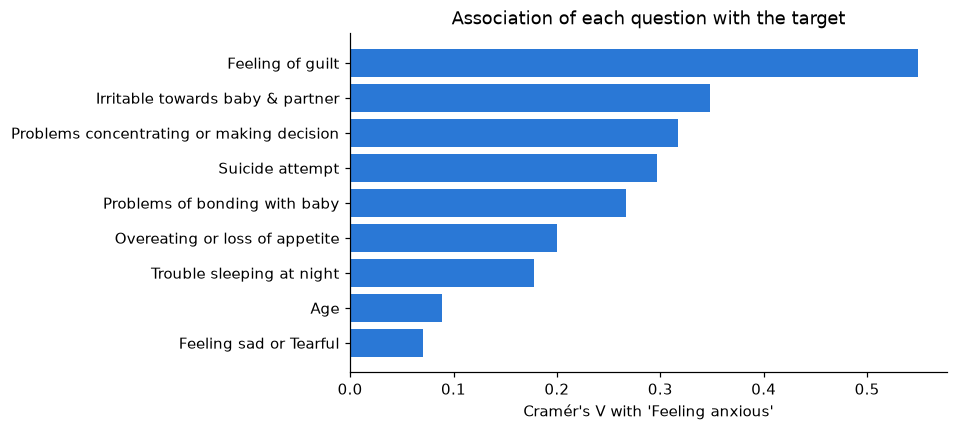

In [11]:
# Task 10: Figure — strength of association with the target (Cramér's V)
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

association = pd.Series({f: cramers_v(data[f], data[TARGET]) for f in FEATURES}).sort_values()
plt.barh(association.index, association.values, color=BLUE)
plt.xlabel("Cramér's V with 'Feeling anxious'")
plt.title("Association of each question with the target")
plt.savefig(RESULTS / "fig03_cramers_v.png")
plt.show()

## Part C — Preparing the data

In [12]:
# Task 11: Turn answers into numbers
encoder = OrdinalEncoder()
X = pd.DataFrame(encoder.fit_transform(data[FEATURES]).astype(int), columns=FEATURES)
y = (data[TARGET] == "Yes").astype(int).to_numpy()

ANSWERS = {f: list(c) for f, c in zip(FEATURES, encoder.categories_)}   # code -> answer text
X.head()

,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,2,2,3,1,3,2,1,2,2
1,3,2,0,0,3,2,3,2,0
2,2,2,0,2,3,2,1,1,0
3,2,2,3,2,3,0,0,0,0
4,3,2,0,1,3,0,1,2,0


In [13]:
# Task 12: Train / test split (80% / 20%, stratified)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Anxious share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (1202, 9)  Test: (301, 9)
Anxious share  train: 0.652  test: 0.651


In [14]:
# Task 13: A small helper — one-hot encoding inside a pipeline
def with_onehot(model):
    return make_pipeline(OneHotEncoder(handle_unknown="ignore", sparse_output=False), model)

models = {}        # every competing model is stored here

## Part D — The seven competing models

In [15]:
# Task 14: Model 1 — Logistic Regression
# Why: simple and transparent baseline; shows what a linear model can do.
models["Logistic Regression"] = with_onehot(LogisticRegression(max_iter=2000))

In [16]:
# Task 15: Model 2 — Random Forest
# Why: many independent trees voting together; a strong, stable classic.
models["Random Forest"] = with_onehot(RandomForestClassifier(n_estimators=300, random_state=SEED))

In [17]:
# Task 16: Model 3 — XGBoost, tuned with Optuna
# Why: the most widely used boosting model in health-ML papers.
# Optuna tries 25 settings; each is scored by 3-fold CV on the training set only.
def xgb_objective(trial):
    model = with_onehot(XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        random_state=SEED))
    return cross_val_score(model, X_train, y_train, cv=3, scoring="accuracy").mean()

xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
xgb_study.optimize(xgb_objective, n_trials=25)
print("Best CV accuracy:", round(xgb_study.best_value, 4))
print("Best settings   :", xgb_study.best_params)

models["XGBoost"] = with_onehot(XGBClassifier(**xgb_study.best_params, random_state=SEED))

Best CV accuracy: 0.9567
Best settings   : {'n_estimators': 303, 'max_depth': 5, 'learning_rate': 0.22641155795282505, 'subsample': 0.6970693462829105, 'colsample_bytree': 0.7077752891882042}


In [18]:
# Task 17: Model 4 — LightGBM, tuned with Optuna
# Why: a faster boosting model that grows trees leaf by leaf.
def lgbm_objective(trial):
    model = with_onehot(LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        num_leaves=trial.suggest_int("num_leaves", 8, 64),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 1, 20),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        random_state=SEED, verbose=-1))
    return cross_val_score(model, X_train, y_train, cv=3, scoring="accuracy").mean()

lgbm_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
lgbm_study.optimize(lgbm_objective, n_trials=25)
print("Best CV accuracy:", round(lgbm_study.best_value, 4))
print("Best settings   :", lgbm_study.best_params)

models["LightGBM"] = with_onehot(LGBMClassifier(**lgbm_study.best_params, random_state=SEED, verbose=-1))

Best CV accuracy: 0.9576
Best settings   : {'n_estimators': 285, 'num_leaves': 56, 'learning_rate': 0.1608285725063366, 'min_child_samples': 9, 'colsample_bytree': 0.7523414979630315}


In [19]:
# Task 18: Model 5 — CatBoost
# Why: boosting designed for categorical data, like these survey answers.
models["CatBoost"] = with_onehot(CatBoostClassifier(iterations=400, depth=6, learning_rate=0.1,
                                                    random_seed=SEED, verbose=0,
                                                    allow_writing_files=False))

In [20]:
# Task 19: Model 6 — MLP neural network
# Why: represents deep learning (a small neural network).
models["MLP Neural Net"] = with_onehot(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=SEED))

In [21]:
# Task 20: Model 7 — the proposed Hybrid Stack
# Why: the four base models come from different families and make different mistakes.
# Level 0: CatBoost, XGBoost, Random Forest and MLP each give a probability.
# Level 1: a logistic regression (meta-learner) learns how much to trust each of them.
# cv=5 means the meta-learner only sees predictions for people the base model was not trained on.
base_models = [
    ("catboost", models["CatBoost"]),
    ("xgboost", models["XGBoost"]),
    ("forest", models["Random Forest"]),
    ("mlp", models["MLP Neural Net"]),
]
models[HYBRID] = StackingClassifier(estimators=base_models, final_estimator=LogisticRegression(max_iter=2000),
                                    stack_method="predict_proba", cv=5)

In [22]:
# Task 21: List of competitors
for number, name in enumerate(models, start=1):
    print(number, name)

1 Logistic Regression
2 Random Forest
3 XGBoost
4 LightGBM
5 CatBoost
6 MLP Neural Net
7 Hybrid Stack (proposed)


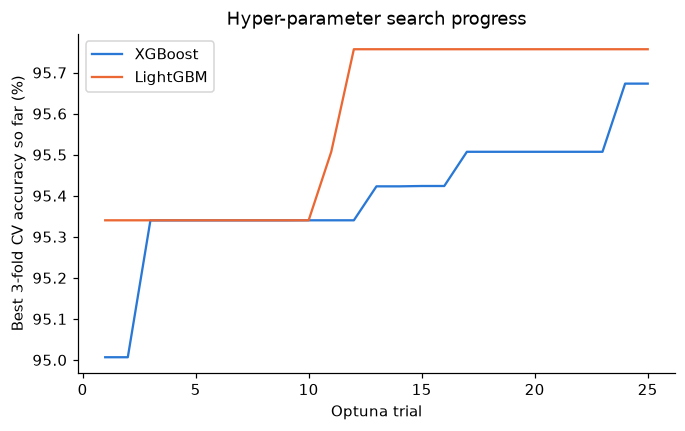

In [23]:
# Task 22: Figure — how Optuna improved over its trials
for study, label, colour in [(xgb_study, "XGBoost", BLUE), (lgbm_study, "LightGBM", ORANGE)]:
    best_so_far = np.maximum.accumulate([t.value for t in study.trials])
    plt.plot(range(1, len(best_so_far) + 1), best_so_far * 100, label=label, color=colour)
plt.xlabel("Optuna trial")
plt.ylabel("Best 3-fold CV accuracy so far (%)")
plt.title("Hyper-parameter search progress")
plt.legend()
plt.savefig(RESULTS / "fig04_optuna_progress.png")
plt.show()

## Part E — Cross-validation competition

In [24]:
# Task 23: 10-fold stratified cross-validation on the training set
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
cv_scores = {}
for name, model in models.items():
    start = time.time()
    cv_scores[name] = cross_val_score(model, X_train, y_train, cv=folds, scoring="accuracy")
    print(f"{name:26s} {cv_scores[name].mean() * 100:.2f}%  ({time.time() - start:.0f}s)")
cv_scores = pd.DataFrame(cv_scores)

Logistic Regression        82.70%  (0s)
Random Forest              97.92%  (2s)
XGBoost                    98.00%  (5s)
LightGBM                   98.08%  (12s)
CatBoost                   98.25%  (3s)
MLP Neural Net             97.59%  (3s)
Hybrid Stack (proposed)    98.00%  (61s)


In [25]:
# Task 24: Cross-validation table (mean ± standard deviation)
cv_table = pd.DataFrame({"cv_accuracy_mean_%": cv_scores.mean() * 100,
                         "cv_accuracy_std_%": cv_scores.std() * 100}).round(2)
cv_table = cv_table.sort_values("cv_accuracy_mean_%", ascending=False)
cv_table.to_csv(RESULTS / "cv_results.csv")
cv_table

,cv_accuracy_mean_%,cv_accuracy_std_%
CatBoost,98.25,1.44
LightGBM,98.08,1.47
XGBoost,98.00,1.13
Hybrid Stack (proposed),98.00,1.26
Random Forest,97.92,1.37
MLP Neural Net,97.59,1.39
Logistic Regression,82.70,2.34


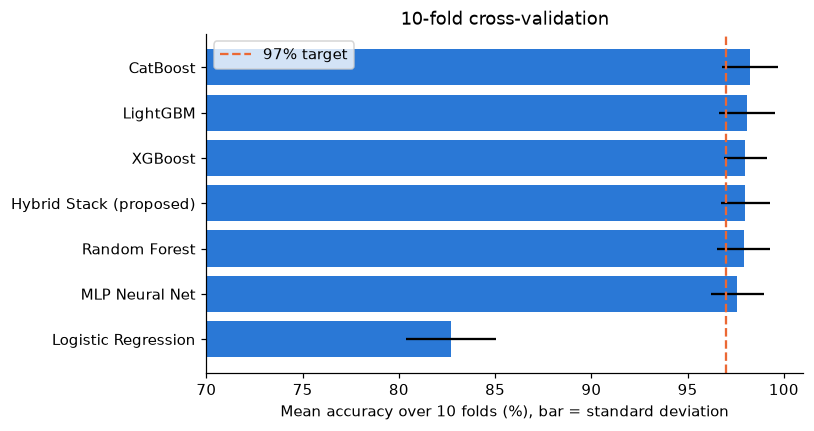

In [26]:
# Task 25: Figure — cross-validation accuracy of every model
plt.barh(cv_table.index[::-1], cv_table["cv_accuracy_mean_%"][::-1], xerr=cv_table["cv_accuracy_std_%"][::-1], color=BLUE)
plt.axvline(97, color=ORANGE, linestyle="--", label="97% target")
plt.xlim(70, 101)
plt.xlabel("Mean accuracy over 10 folds (%), bar = standard deviation")
plt.title("10-fold cross-validation")
plt.legend()
plt.savefig(RESULTS / "fig05_cv_accuracy.png")
plt.show()

## Part F — Final test on the held-out 20%

In [27]:
# Task 26: Train every model on the full training set
for name, model in models.items():
    model.fit(X_train, y_train)
print("All models trained.")

All models trained.


In [28]:
# Task 27: A function that computes all metrics
def all_metrics(model, X_part, y_part):
    probability = model.predict_proba(X_part)[:, 1]
    predicted = (probability >= 0.5).astype(int)
    return {
        "accuracy": metrics.accuracy_score(y_part, predicted) * 100,
        "balanced_accuracy": metrics.balanced_accuracy_score(y_part, predicted) * 100,
        "precision": metrics.precision_score(y_part, predicted) * 100,
        "recall": metrics.recall_score(y_part, predicted) * 100,
        "specificity": metrics.recall_score(y_part, predicted, pos_label=0) * 100,
        "f1": metrics.f1_score(y_part, predicted) * 100,
        "mcc": metrics.matthews_corrcoef(y_part, predicted),
        "roc_auc": metrics.roc_auc_score(y_part, probability),
        "brier": metrics.brier_score_loss(y_part, probability),
    }

In [29]:
# Task 28: Test-set results table
test_table = pd.DataFrame({name: all_metrics(model, X_test, y_test) for name, model in models.items()}).T
test_table = test_table.sort_values("accuracy", ascending=False)
test_table.round(3).to_csv(RESULTS / "test_results.csv")
test_table.round(3)

,accuracy,balanced_accuracy,precision,recall,specificity,f1,mcc,roc_auc,brier
CatBoost,100.000,100.000,100.000,100.000,100.000,100.000,1.000,1.000,0.002
Random Forest,99.336,99.490,100.000,98.980,100.000,99.487,0.986,1.000,0.014
MLP Neural Net,98.671,98.980,100.000,97.959,100.000,98.969,0.971,0.997,0.015
Hybrid Stack (proposed),98.671,98.980,100.000,97.959,100.000,98.969,0.971,1.000,0.007
XGBoost,97.674,98.214,100.000,96.429,100.000,98.182,0.951,0.997,0.016
LightGBM,97.674,98.214,100.000,96.429,100.000,98.182,0.951,1.000,0.022
Logistic Regression,81.728,78.673,84.058,88.776,68.571,86.352,0.590,0.895,0.122


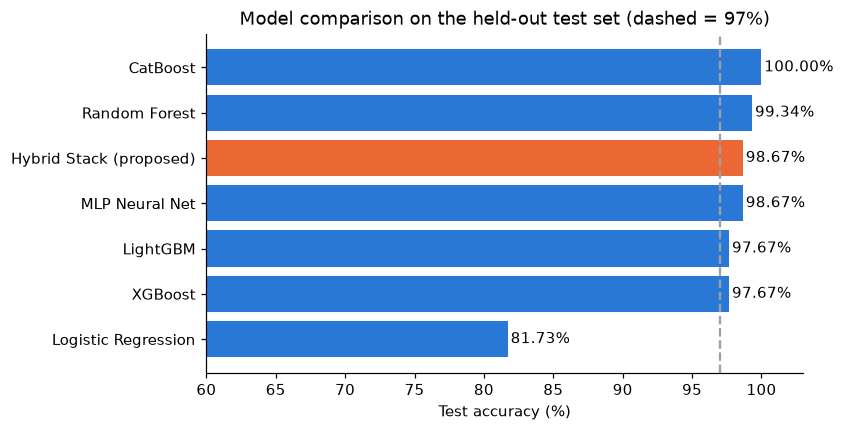

In [30]:
# Task 29: Figure — test accuracy of every model
ordered = test_table["accuracy"].sort_values()
colours = [ORANGE if m == HYBRID else BLUE for m in ordered.index]
plt.barh(ordered.index, ordered.values, color=colours)
for i, v in enumerate(ordered.values):
    plt.text(v + 0.2, i, f"{v:.2f}%", va="center")
plt.axvline(97, color=GREY, linestyle="--")
plt.xlim(60, 103)
plt.xlabel("Test accuracy (%)")
plt.title("Model comparison on the held-out test set (dashed = 97%)")
plt.savefig(RESULTS / "fig06_test_accuracy.png")
plt.show()

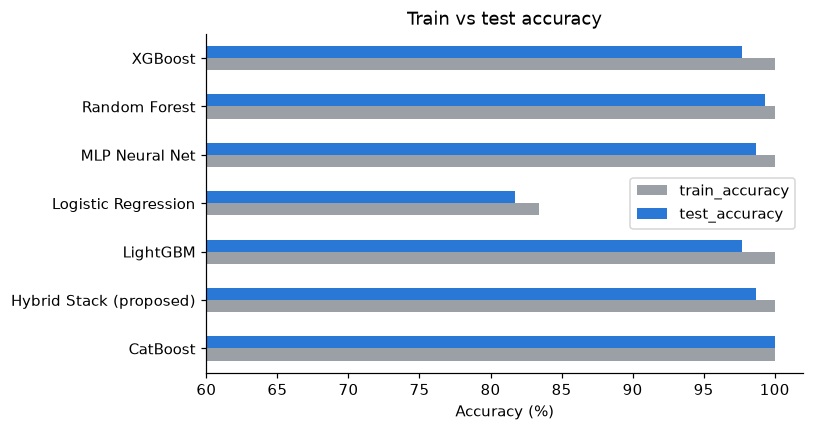

,train_accuracy,test_accuracy,gap
CatBoost,100.00,100.00,0.00
Hybrid Stack (proposed),100.00,98.67,1.33
LightGBM,100.00,97.67,2.33
Logistic Regression,83.44,81.73,1.72
MLP Neural Net,100.00,98.67,1.33
Random Forest,100.00,99.34,0.66
XGBoost,100.00,97.67,2.33


In [31]:
# Task 30: Overfitting check — train accuracy vs test accuracy
gap_table = pd.DataFrame({
    "train_accuracy": {n: all_metrics(m, X_train, y_train)["accuracy"] for n, m in models.items()},
    "test_accuracy": test_table["accuracy"]})
gap_table["gap"] = gap_table["train_accuracy"] - gap_table["test_accuracy"]
gap_table.round(2).to_csv(RESULTS / "train_vs_test.csv")

gap_table[["train_accuracy", "test_accuracy"]].plot.barh(color=[GREY, BLUE], figsize=(7, 4))
plt.xlim(60, 102)
plt.xlabel("Accuracy (%)")
plt.title("Train vs test accuracy")
plt.savefig(RESULTS / "fig07_train_vs_test.png")
plt.show()
gap_table.round(2)

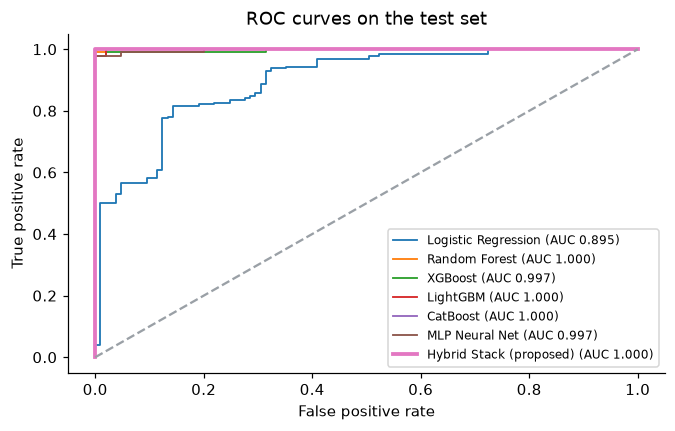

In [32]:
# Task 31: Figure — ROC curves
for name, model in models.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, linewidth=2.5 if name == HYBRID else 1.2,
             label=f"{name} (AUC {test_table.loc[name, 'roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], color=GREY, linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(fontsize=8)
plt.savefig(RESULTS / "fig08_roc_curves.png")
plt.show()

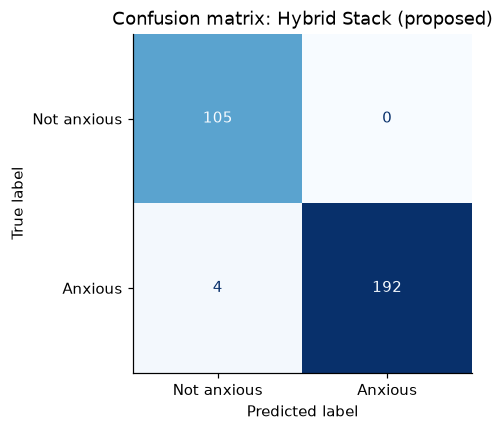

,true_negative,false_positive,false_negative,true_positive
Logistic Regression,72,33,22,174
Random Forest,105,0,2,194
XGBoost,105,0,7,189
LightGBM,105,0,7,189
CatBoost,105,0,0,196
MLP Neural Net,105,0,4,192
Hybrid Stack (proposed),105,0,4,192


In [33]:
# Task 32: Figure — confusion matrix of the Hybrid Stack (and a table for every model)
metrics.ConfusionMatrixDisplay.from_estimator(models[HYBRID], X_test, y_test, display_labels=["Not anxious", "Anxious"],
                                              cmap="Blues", colorbar=False)
plt.title("Confusion matrix: " + HYBRID)
plt.savefig(RESULTS / "fig09_confusion_matrix.png")
plt.show()

# the same four numbers for every model, as a table
confusion_table = pd.DataFrame({name: metrics.confusion_matrix(y_test, model.predict(X_test)).ravel() for name, model in models.items()},
                               index=["true_negative", "false_positive", "false_negative", "true_positive"]).T
confusion_table.to_csv(RESULTS / "confusion_matrices.csv")
confusion_table

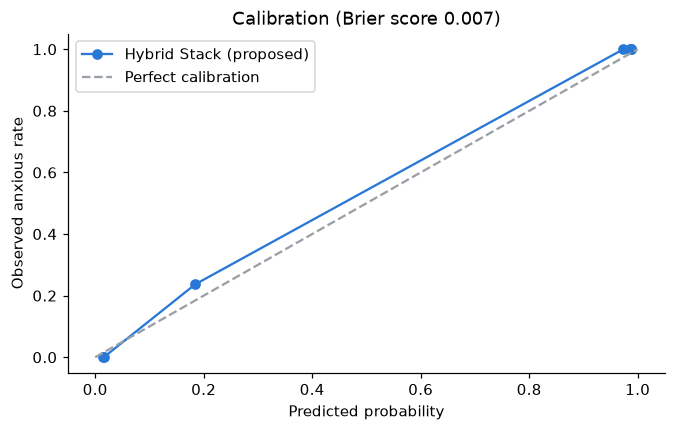

In [34]:
# Task 33: Figure — calibration of the Hybrid Stack
hybrid = models[HYBRID]
hybrid_probability = hybrid.predict_proba(X_test)[:, 1]
observed, predicted_mean = calibration_curve(y_test, hybrid_probability, n_bins=8, strategy="quantile")
plt.plot(predicted_mean, observed, marker="o", color=BLUE, label=HYBRID)
plt.plot([0, 1], [0, 1], color=GREY, linestyle="--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Observed anxious rate")
plt.title(f"Calibration (Brier score {test_table.loc[HYBRID, 'brier']:.3f})")
plt.legend()
plt.savefig(RESULTS / "fig10_calibration.png")
plt.show()

In [35]:
# Task 34: Statistical tests on the 10 cross-validation folds
friedman = stats.friedmanchisquare(*[cv_scores[m] for m in cv_scores.columns])
print(f"Friedman test: chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.2g}")

rows = []
for name in cv_scores.columns.drop(HYBRID):
    difference = cv_scores[HYBRID] - cv_scores[name]
    p = 1.0 if (difference == 0).all() else stats.wilcoxon(cv_scores[HYBRID], cv_scores[name]).pvalue
    rows.append({"hybrid_vs": name, "mean_difference_points": difference.mean() * 100, "p_value": p})
stat_table = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
stat_table["p_holm"] = np.minimum(1, np.maximum.accumulate(stat_table["p_value"] * (len(stat_table) - stat_table.index)))
stat_table.round(4).to_csv(RESULTS / "statistical_tests.csv", index=False)
stat_table.round(4)

Friedman test: chi2 = 35.87, p = 2.9e-06


,hybrid_vs,mean_difference_points,p_value,p_holm
0,Logistic Regression,15.3058,0.002,0.0117
1,CatBoost,-0.2500,0.375,1.0000
2,MLP Neural Net,0.4146,0.375,1.0000
3,LightGBM,-0.0826,0.750,1.0000
4,Random Forest,0.0820,1.000,1.0000
5,XGBoost,0.0000,1.000,1.0000


In [36]:
# Task 35: McNemar test and bootstrap confidence interval on the test set
hybrid_correct = hybrid.predict(X_test) == y_test
rows = []
for name, model in models.items():
    if name == HYBRID:
        continue
    other_correct = model.predict(X_test) == y_test
    only_hybrid = int((hybrid_correct & ~other_correct).sum())
    only_other = int((~hybrid_correct & other_correct).sum())
    p = stats.binomtest(only_hybrid, only_hybrid + only_other, 0.5).pvalue if only_hybrid + only_other else 1.0
    rows.append({"hybrid_vs": name, "only_hybrid_right": only_hybrid, "only_other_right": only_other, "p_value": round(p, 4)})
mcnemar_table = pd.DataFrame(rows)
mcnemar_table.to_csv(RESULTS / "mcnemar_tests.csv", index=False)

rng = np.random.default_rng(SEED)
boot = [hybrid_correct[rng.integers(0, len(y_test), len(y_test))].mean() * 100 for _ in range(2000)]
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f"Hybrid Stack test accuracy: {hybrid_correct.mean() * 100:.2f}%  (95% bootstrap CI {ci_low:.2f}-{ci_high:.2f}%)")
mcnemar_table

Hybrid Stack test accuracy: 98.67%  (95% bootstrap CI 97.34-99.67%)


,hybrid_vs,only_hybrid_right,only_other_right,p_value
0,Logistic Regression,53,2,0.000
1,Random Forest,0,2,0.500
2,XGBoost,3,0,0.250
3,LightGBM,3,0,0.250
4,CatBoost,0,4,0.125
5,MLP Neural Net,0,0,1.000


## Part G — Explainable AI (SHAP and LIME)

In [37]:
# Task 36: Prepare the people to explain and the prediction function
N_EXPLAIN = 100
explain_people = X_test.iloc[:N_EXPLAIN]
background = X_train.sample(30, random_state=SEED)       # reference people for SHAP

def predict_anxious(values):
    # probability of 'anxious' from the Hybrid Stack
    return hybrid.predict_proba(pd.DataFrame(values, columns=FEATURES))[:, 1]

def predict_both(values):
    return hybrid.predict_proba(pd.DataFrame(values, columns=FEATURES))

In [38]:
# Task 37: Compute SHAP values
start = time.time()
shap_explainer = shap.Explainer(predict_anxious, background)
shap_result = shap_explainer(explain_people)
shap_seconds = (time.time() - start) / N_EXPLAIN

shap_values = pd.DataFrame(shap_result.values, columns=FEATURES)
print(f"SHAP: {shap_seconds:.2f} seconds per person")

ExactExplainer explainer: 101it [00:20,  2.79it/s]                         

SHAP: 0.20 seconds per person


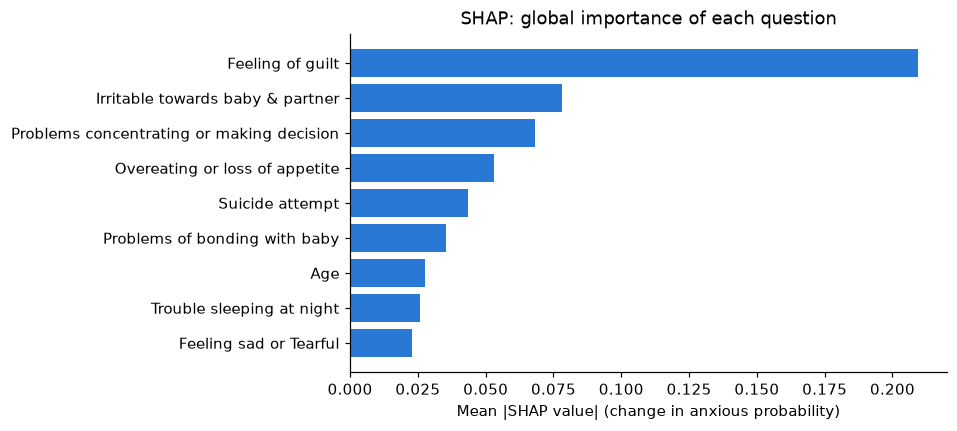

In [39]:
# Task 38: Figure — SHAP global importance
shap_importance = shap_values.abs().mean().sort_values()
plt.barh(shap_importance.index, shap_importance.values, color=BLUE)
plt.xlabel("Mean |SHAP value| (change in anxious probability)")
plt.title("SHAP: global importance of each question")
plt.savefig(RESULTS / "fig11_shap_importance.png")
plt.show()

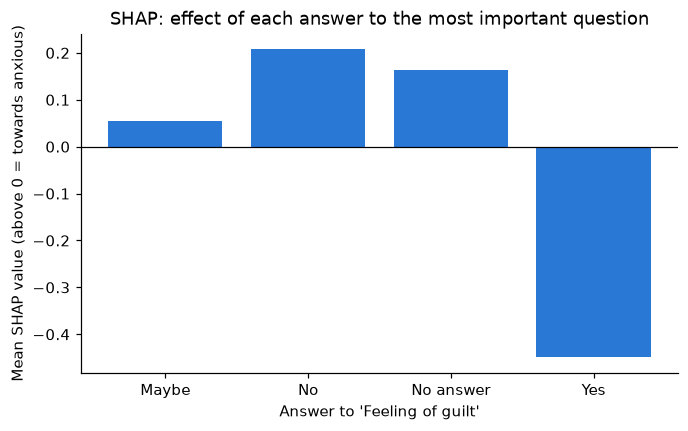

In [40]:
# Task 39: Figure — SHAP effect of each answer to the most important question
top_question = shap_importance.index[-1]
answer_text = explain_people[top_question].map(lambda code: ANSWERS[top_question][code]).to_numpy()
effect = shap_values[top_question].groupby(answer_text).mean()
plt.bar(effect.index, effect.values, color=BLUE)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Mean SHAP value (above 0 = towards anxious)")
plt.xlabel(f"Answer to '{top_question}'")
plt.title("SHAP: effect of each answer to the most important question")
plt.savefig(RESULTS / "fig12_shap_top_question.png")
plt.show()

Predicted anxious probability: 0.023   True label: 0
SHAP check: base 0.566 + contributions -0.542 = 0.023


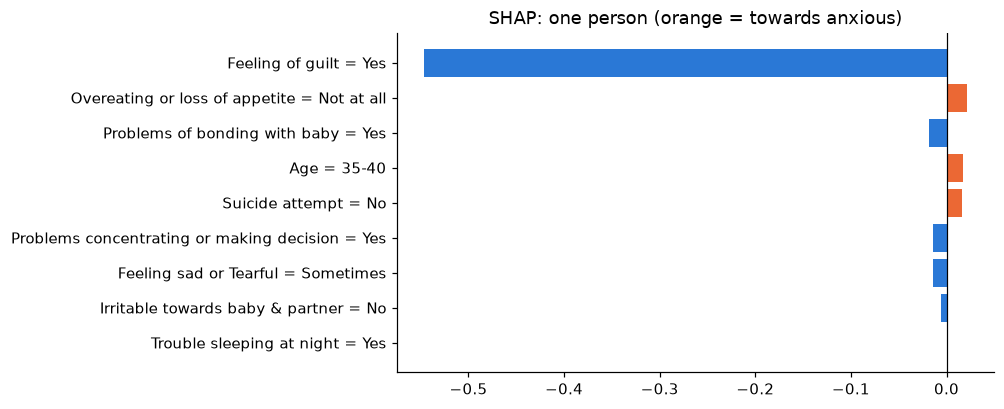

In [41]:
# Task 40: Figure — SHAP explanation of one person
PERSON = 0
person_answers = {f: ANSWERS[f][explain_people.iloc[PERSON][f]] for f in FEATURES}
labels = [f"{f} = {person_answers[f]}" for f in FEATURES]

def plot_one_person(values, title, filename):
    order = np.argsort(np.abs(values))
    plt.barh([labels[i] for i in order], values[order], color=[ORANGE if v > 0 else BLUE for v in values[order]])
    plt.axvline(0, color="black", linewidth=0.8)
    plt.title(title)
    plt.savefig(RESULTS / filename)
    plt.show()

p = predict_anxious(explain_people.iloc[[PERSON]])[0]
print(f"Predicted anxious probability: {p:.3f}   True label: {y_test[PERSON]}")
print(f"SHAP check: base {shap_result.base_values[PERSON]:.3f} + contributions {shap_values.iloc[PERSON].sum():.3f} = {shap_result.base_values[PERSON] + shap_values.iloc[PERSON].sum():.3f}")
plot_one_person(shap_values.iloc[PERSON].to_numpy(), "SHAP: one person (orange = towards anxious)", "fig13_shap_one_person.png")

In [42]:
# Task 41: Compute LIME explanations
lime_explainer = LimeTabularExplainer(
    X_train.to_numpy(), feature_names=FEATURES, class_names=["Not anxious", "Anxious"],
    categorical_features=list(range(len(FEATURES))),
    categorical_names={i: ANSWERS[f] for i, f in enumerate(FEATURES)}, random_state=SEED)

def lime_for(person_row, explainer=lime_explainer):
    explanation = explainer.explain_instance(person_row.to_numpy(), predict_both, num_features=len(FEATURES), num_samples=1000)
    weights = dict(explanation.as_map()[1])                  # {feature number: weight}
    return [weights[i] for i in range(len(FEATURES))]

start = time.time()
lime_values = pd.DataFrame([lime_for(explain_people.iloc[i]) for i in range(N_EXPLAIN)], columns=FEATURES)
lime_seconds = (time.time() - start) / N_EXPLAIN
print(f"LIME: {lime_seconds:.2f} seconds per person")

LIME: 0.04 seconds per person


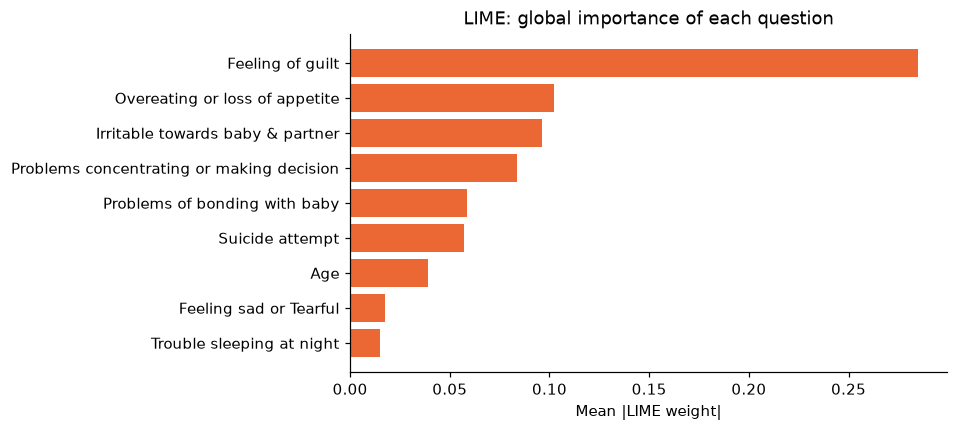

In [43]:
# Task 42: Figure — LIME global importance
lime_importance = lime_values.abs().mean().sort_values()
plt.barh(lime_importance.index, lime_importance.values, color=ORANGE)
plt.xlabel("Mean |LIME weight|")
plt.title("LIME: global importance of each question")
plt.savefig(RESULTS / "fig14_lime_importance.png")
plt.show()

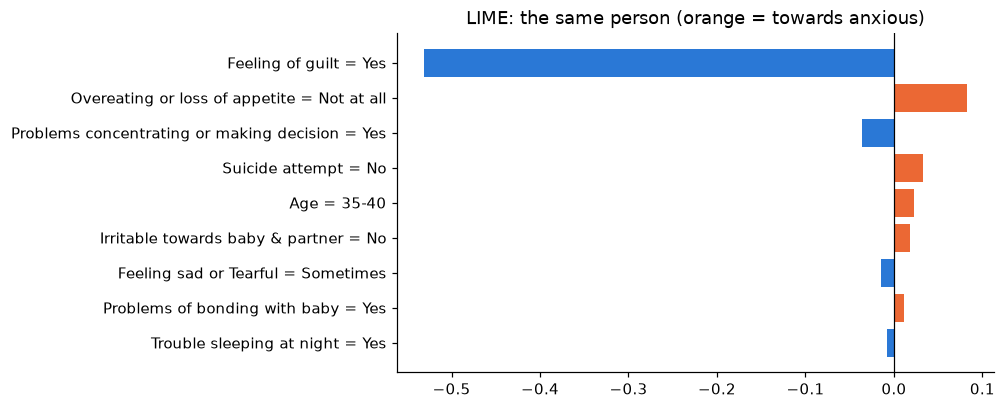

In [44]:
# Task 43: Figure — LIME explanation of the same person
plot_one_person(lime_values.iloc[PERSON].to_numpy(), "LIME: the same person (orange = towards anxious)", "fig15_lime_one_person.png")

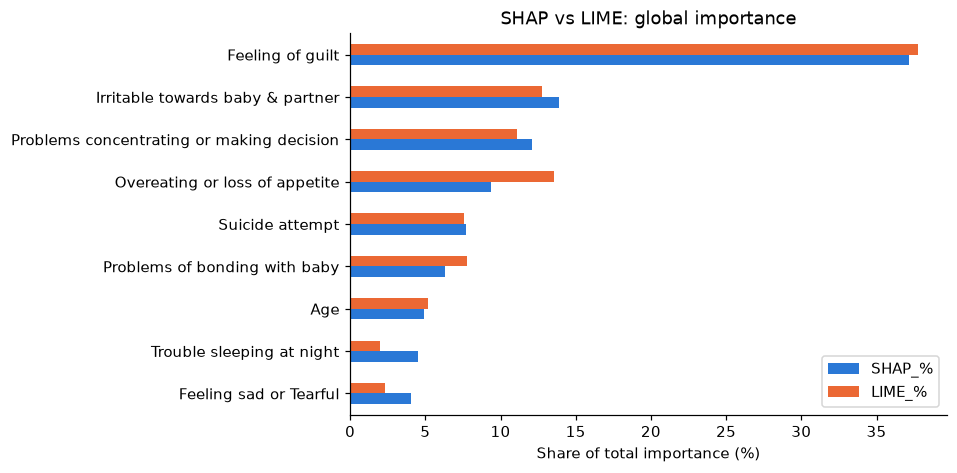

In [45]:
# Task 44: SHAP vs LIME (1) — do they rank the questions the same way?
compare = pd.DataFrame({"SHAP_%": shap_importance / shap_importance.sum() * 100,
                        "LIME_%": lime_importance / lime_importance.sum() * 100}).sort_values("SHAP_%")
compare.round(2).to_csv(RESULTS / "shap_vs_lime_importance.csv")

compare.plot.barh(color=[BLUE, ORANGE], figsize=(7, 4.5))
plt.xlabel("Share of total importance (%)")
plt.title("SHAP vs LIME: global importance")
plt.savefig(RESULTS / "fig16_shap_vs_lime.png")
plt.show()

In [46]:
# Task 45: SHAP vs LIME (2) — agreement
global_spearman = stats.spearmanr(compare["SHAP_%"], compare["LIME_%"]).statistic

S, L = shap_values.to_numpy(), lime_values.to_numpy()
person_spearman = np.mean([stats.spearmanr(np.abs(S[i]), np.abs(L[i])).statistic for i in range(N_EXPLAIN)])
same_top1 = np.mean(np.abs(S).argmax(axis=1) == np.abs(L).argmax(axis=1)) * 100
top3_overlap = np.mean([len(set(np.argsort(-np.abs(S[i]))[:3]) & set(np.argsort(-np.abs(L[i]))[:3])) / 3
                        for i in range(N_EXPLAIN)]) * 100
same_sign = np.mean(np.sign(S) == np.sign(L)) * 100

print(f"Global Spearman rank correlation : {global_spearman:.3f}")
print(f"Mean per-person Spearman         : {person_spearman:.3f}")
print(f"Same top question                : {same_top1:.1f}% of people")
print(f"Top-3 overlap                    : {top3_overlap:.1f}%")
print(f"Same direction (+/-)             : {same_sign:.1f}% of all contributions")

Global Spearman rank correlation : 0.917
Mean per-person Spearman         : 0.535
Same top question                : 70.0% of people
Top-3 overlap                    : 64.3%
Same direction (+/-)             : 77.3% of all contributions


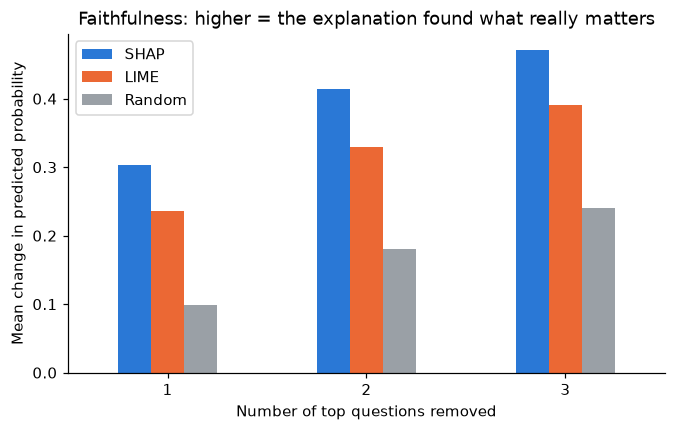

,SHAP,LIME,Random
questions_removed,,,
1,0.3038,0.2366,0.0984
2,0.4137,0.3296,0.1811
3,0.4712,0.3912,0.2405


In [47]:
# Task 46: SHAP vs LIME (3) — faithfulness (deletion test)
def change_after_removing(person_row, feature_numbers):
    changed = pd.concat([person_row.to_frame().T] * len(background), ignore_index=True)
    for j in feature_numbers:
        changed[FEATURES[j]] = background[FEATURES[j]].to_numpy()
    return abs(predict_anxious(person_row.to_frame().T)[0] - predict_anxious(changed).mean())

rng = np.random.default_rng(SEED)
rows = []
for k in [1, 2, 3]:
    by_shap, by_lime, by_random = [], [], []
    for i in range(N_EXPLAIN):
        person_row = explain_people.iloc[i]
        by_shap.append(change_after_removing(person_row, np.argsort(-np.abs(S[i]))[:k]))
        by_lime.append(change_after_removing(person_row, np.argsort(-np.abs(L[i]))[:k]))
        by_random.append(change_after_removing(person_row, rng.choice(len(FEATURES), k, replace=False)))
    rows.append({"questions_removed": k, "SHAP": np.mean(by_shap), "LIME": np.mean(by_lime), "Random": np.mean(by_random)})
faithfulness = pd.DataFrame(rows).set_index("questions_removed")
faithfulness.round(4).to_csv(RESULTS / "shap_vs_lime_faithfulness.csv")

faithfulness.plot.bar(color=[BLUE, ORANGE, GREY], rot=0)
plt.ylabel("Mean change in predicted probability")
plt.xlabel("Number of top questions removed")
plt.title("Faithfulness: higher = the explanation found what really matters")
plt.savefig(RESULTS / "fig17_faithfulness.png")
plt.show()
faithfulness.round(4)

In [48]:
# Task 47: SHAP vs LIME (4) — stability
N_STABLE = 20
lime_explainer_2 = LimeTabularExplainer(
    X_train.to_numpy(), feature_names=FEATURES, class_names=["Not anxious", "Anxious"],
    categorical_features=list(range(len(FEATURES))),
    categorical_names={i: ANSWERS[f] for i, f in enumerate(FEATURES)}, random_state=SEED + 1)
lime_again = np.array([lime_for(explain_people.iloc[i], lime_explainer_2) for i in range(N_STABLE)])

shap_again = shap.Explainer(predict_anxious, X_train.sample(30, random_state=SEED + 1))(explain_people.iloc[:N_STABLE]).values

lime_stability = np.mean([stats.spearmanr(L[i], lime_again[i]).statistic for i in range(N_STABLE)])
shap_stability = np.mean([stats.spearmanr(S[i], shap_again[i]).statistic for i in range(N_STABLE)])
print(f"SHAP stability (new reference people): {shap_stability:.3f}")
print(f"LIME stability (new random seed)     : {lime_stability:.3f}")

SHAP stability (new reference people): 0.917
LIME stability (new random seed)     : 0.893


In [49]:
# Task 48: SHAP vs LIME — summary table
xai_summary = pd.DataFrame({
    "SHAP": {"Top question": shap_importance.index[-1],
             "Top-3 questions": ", ".join(shap_importance.index[::-1][:3]),
             "Faithfulness (top-1 removed)": round(faithfulness.loc[1, "SHAP"], 4),
             "Faithfulness (top-3 removed)": round(faithfulness.loc[3, "SHAP"], 4),
             "Stability (Spearman)": round(shap_stability, 3),
             "Seconds per person": round(shap_seconds, 2),
             "Adds up to the prediction": "Yes"},
    "LIME": {"Top question": lime_importance.index[-1],
             "Top-3 questions": ", ".join(lime_importance.index[::-1][:3]),
             "Faithfulness (top-1 removed)": round(faithfulness.loc[1, "LIME"], 4),
             "Faithfulness (top-3 removed)": round(faithfulness.loc[3, "LIME"], 4),
             "Stability (Spearman)": round(lime_stability, 3),
             "Seconds per person": round(lime_seconds, 2),
             "Adds up to the prediction": "No"}})
agreement = pd.Series({"Global Spearman": round(global_spearman, 3), "Per-person Spearman": round(person_spearman, 3),
                       "Same top question (%)": round(same_top1, 1), "Top-3 overlap (%)": round(top3_overlap, 1),
                       "Same direction (%)": round(same_sign, 1)}, name="value")
xai_summary.to_csv(RESULTS / "shap_vs_lime_summary.csv")
agreement.to_csv(RESULTS / "shap_vs_lime_agreement.csv")
print(agreement.to_string())
xai_summary

Global Spearman           0.917
Per-person Spearman       0.535
Same top question (%)    70.000
Top-3 overlap (%)        64.300
Same direction (%)       77.300


,SHAP,LIME
Top question,Feeling of guilt,Feeling of guilt
Top-3 questions,"Feeling of guilt, Irritable towards baby & par...","Feeling of guilt, Overeating or loss of appeti..."
Faithfulness (top-1 removed),0.3038,0.2366
Faithfulness (top-3 removed),0.4712,0.3912
Stability (Spearman),0.917,0.893
Seconds per person,0.2,0.04
Adds up to the prediction,Yes,No


In [50]:
# Task 49: Table — do the seven models agree on what is important? (permutation importance)
# Permutation importance: shuffle one question and see how many accuracy points are lost.
importance_by_model = pd.DataFrame({
    name: permutation_importance(model, X_test, y_test, n_repeats=5, random_state=SEED, scoring="accuracy").importances_mean
    for name, model in models.items()}, index=FEATURES) * 100
importance_by_model = importance_by_model.sort_values(HYBRID, ascending=False)
importance_by_model.round(2).to_csv(RESULTS / "permutation_importance_by_model.csv")
importance_by_model.round(1)

,Logistic Regression,Random Forest,XGBoost,LightGBM,CatBoost,MLP Neural Net,Hybrid Stack (proposed)
Feeling of guilt,7.7,20.5,18.7,19.5,20.7,19.6,19.9
Problems concentrating or making decision,2.3,6.0,9.7,11.5,8.4,11.0,7.0
Overeating or loss of appetite,3.3,6.6,9.9,8.0,5.2,11.2,5.9
Irritable towards baby & partner,4.8,6.4,8.2,4.8,5.8,7.0,4.5
Trouble sleeping at night,1.0,3.5,4.5,2.1,4.4,4.7,3.8
Suicide attempt,1.3,4.3,3.9,4.1,4.2,6.9,2.9
Age,-0.1,2.1,4.1,4.5,3.6,7.7,2.5
Feeling sad or Tearful,1.0,3.1,2.1,1.3,3.1,7.0,2.0
Problems of bonding with baby,1.9,1.7,3.0,1.2,2.2,8.6,1.1


## Part H — Trustworthy-AI extras

In [51]:
# Task 50: Conformal prediction — an honest "I am not sure"
oof_probability = cross_val_predict(hybrid, X_train, y_train, cv=5, method="predict_proba")
calibration_scores = 1 - oof_probability[np.arange(len(y_train)), y_train]
test_probability = hybrid.predict_proba(X_test)

rows = []
for alpha in [0.10, 0.05, 0.01]:
    n = len(calibration_scores)
    threshold = np.quantile(calibration_scores, min(1, np.ceil((n + 1) * (1 - alpha)) / n))
    in_set = (1 - test_probability) <= threshold                   # True where a class is inside the set
    rows.append({"target_coverage_%": (1 - alpha) * 100,
                 "actual_coverage_%": in_set[np.arange(len(y_test)), y_test].mean() * 100,
                 "average_set_size": in_set.sum(axis=1).mean(),
                 "single_answer_%": (in_set.sum(axis=1) == 1).mean() * 100,
                 "uncertain_both_%": (in_set.sum(axis=1) == 2).mean() * 100,
                 "empty_set_%": (in_set.sum(axis=1) == 0).mean() * 100})
conformal_table = pd.DataFrame(rows)
conformal_table.round(2).to_csv(RESULTS / "conformal_prediction.csv", index=False)
conformal_table.round(2)

,target_coverage_%,actual_coverage_%,average_set_size,single_answer_%,uncertain_both_%,empty_set_%
0,90.0,94.35,0.94,94.35,0.00,5.65
1,95.0,97.01,0.97,97.01,0.00,2.99
2,99.0,100.00,1.03,97.01,2.99,0.00


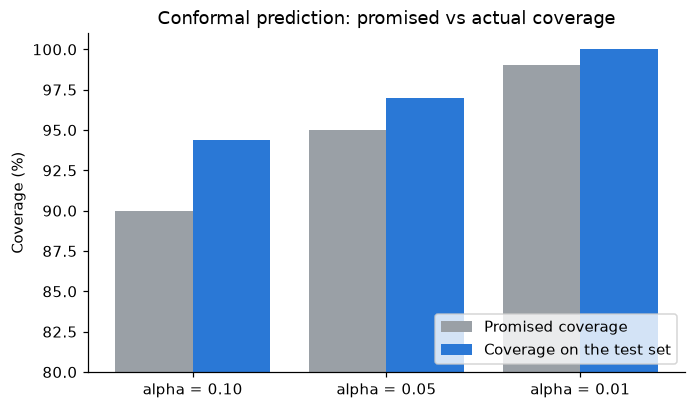

In [52]:
# Task 51: Figure — conformal coverage
positions = np.arange(len(conformal_table))
plt.bar(positions - 0.2, conformal_table["target_coverage_%"], width=0.4, color=GREY, label="Promised coverage")
plt.bar(positions + 0.2, conformal_table["actual_coverage_%"], width=0.4, color=BLUE, label="Coverage on the test set")
plt.xticks(positions, [f"alpha = {1 - c / 100:.2f}" for c in conformal_table["target_coverage_%"]])
plt.ylim(80, 101)
plt.ylabel("Coverage (%)")
plt.title("Conformal prediction: promised vs actual coverage")
plt.legend(loc="lower right")
plt.savefig(RESULTS / "fig19_conformal_coverage.png")
plt.show()

In [53]:
# Task 52: Counterfactual explanation — "what would have to change?"
predicted_anxious = np.where(hybrid_probability >= 0.5)[0]
person_number = predicted_anxious[0]
person_row = X_test.iloc[person_number]
changeable = [f for f in FEATURES if f != "Age"]

found = []
for size in [1, 2]:
    for chosen in combinations(changeable, size):
        options = [range(len(ANSWERS[f])) for f in chosen]
        for new_codes in np.array(np.meshgrid(*options)).T.reshape(-1, size):
            if any(new_codes[i] == person_row[f] for i, f in enumerate(chosen)):
                continue
            changed = person_row.copy()
            changed[list(chosen)] = new_codes
            probability = predict_anxious(changed.to_frame().T)[0]
            if probability < 0.5:
                change_text = "; ".join(f"{f}: {ANSWERS[f][person_row[f]]} -> {ANSWERS[f][c]}" for f, c in zip(chosen, new_codes))
                found.append({"answers_changed": size, "change": change_text, "new_probability": round(probability, 3)})
    if found:
        break

print(f"Person {person_number}: anxious probability {hybrid_probability[person_number]:.3f}")
counterfactuals = pd.DataFrame(found).sort_values("new_probability").head(8).reset_index(drop=True)
counterfactuals.to_csv(RESULTS / "counterfactual_example.csv", index=False)
pd.set_option("display.max_colwidth", None)
counterfactuals

Person 3: anxious probability 0.987


,answers_changed,change,new_probability
0,1,Irritable towards baby & partner: Yes -> Sometimes,0.128
1,1,Irritable towards baby & partner: Yes -> No,0.211


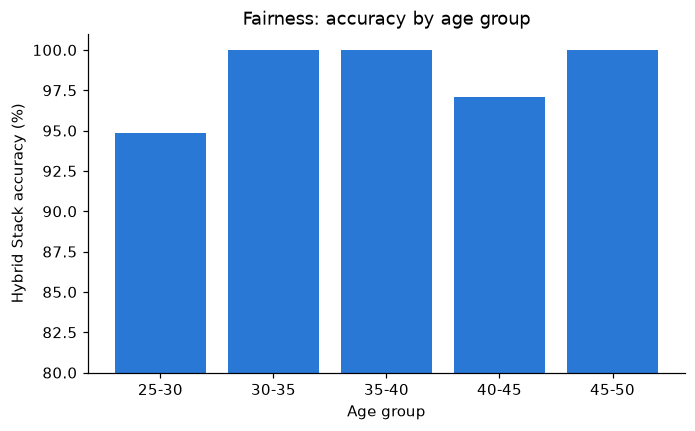

,people,accuracy_%
Age,,
25-30,39,94.87
30-35,78,100.00
35-40,68,100.00
40-45,69,97.10
45-50,47,100.00


In [54]:
# Task 53: Fairness check — accuracy in every age group
age_text = X_test["Age"].map(lambda code: ANSWERS["Age"][code])
fairness = pd.DataFrame({"people": age_text.value_counts(),
                         "accuracy_%": pd.Series(hybrid_correct, index=X_test.index).groupby(age_text).mean() * 100}).sort_index()
fairness.round(2).to_csv(RESULTS / "fairness_by_age.csv")

plt.bar(fairness.index, fairness["accuracy_%"], color=BLUE)
plt.ylim(80, 101)
plt.xlabel("Age group")
plt.ylabel("Hybrid Stack accuracy (%)")
plt.title("Fairness: accuracy by age group")
plt.savefig(RESULTS / "fig20_fairness_by_age.png")
plt.show()
fairness.round(2)

## Part I — Robustness check: duplicate-aware validation

In [55]:
# Task 54: How many test people have a twin in the training set?
train_patterns = set(map(tuple, X_train.to_numpy()))
has_twin = np.array([tuple(row) in train_patterns for row in X_test.to_numpy()])
print(f"Test people with an identical answer pattern in the training set: {has_twin.sum()} of {len(has_twin)} ({has_twin.mean():.1%})")
for label, mask in [("with a twin", has_twin), ("without a twin", ~has_twin)]:
    print(f"Hybrid Stack accuracy on test people {label:15s}: {hybrid_correct[mask].mean() * 100:.2f}%  (n = {mask.sum()})")

Test people with an identical answer pattern in the training set: 281 of 301 (93.4%)
Hybrid Stack accuracy on test people with a twin    : 100.00%  (n = 281)
Hybrid Stack accuracy on test people without a twin : 80.00%  (n = 20)


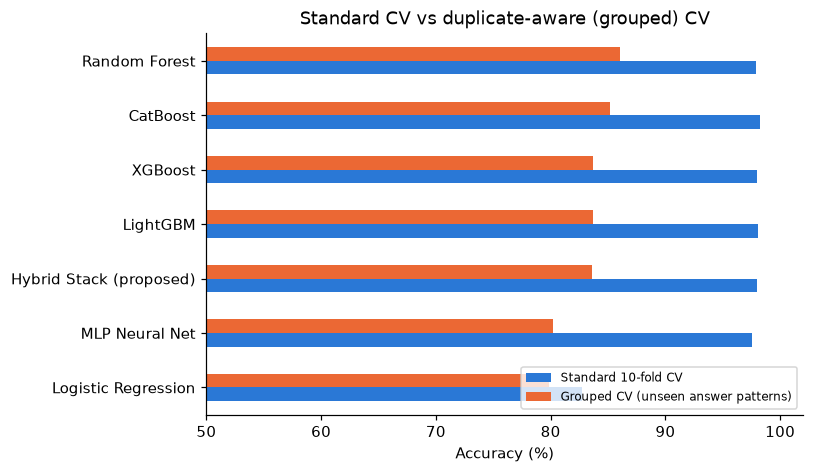

,standard_cv_accuracy_%,grouped_cv_accuracy_%,grouped_cv_balanced_accuracy_%
Random Forest,97.92,86.03,83.76
CatBoost,98.25,85.16,82.78
XGBoost,98.00,83.70,82.46
LightGBM,98.08,83.70,81.84
Hybrid Stack (proposed),98.00,83.63,81.70
MLP Neural Net,97.59,80.17,78.60
Logistic Regression,82.70,79.84,77.01


In [56]:
# Task 55: Grouped 5-fold cross-validation (no answer pattern is shared between training and test)
pattern_id = X.astype(str).agg("-".join, axis=1)
group_folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = {}
for name, model in models.items():
    predicted = cross_val_predict(model, X, y, cv=group_folds, groups=pattern_id)
    rows[name] = {"standard_cv_accuracy_%": cv_scores[name].mean() * 100,
                  "grouped_cv_accuracy_%": metrics.accuracy_score(y, predicted) * 100,
                  "grouped_cv_balanced_accuracy_%": metrics.balanced_accuracy_score(y, predicted) * 100}
robustness = pd.DataFrame(rows).T.sort_values("grouped_cv_accuracy_%", ascending=False)
robustness.round(2).to_csv(RESULTS / "robustness_grouped_cv.csv")

robustness[["standard_cv_accuracy_%", "grouped_cv_accuracy_%"]].iloc[::-1].plot.barh(color=[BLUE, ORANGE], figsize=(7, 4.5))
plt.xlim(50, 102)
plt.xlabel("Accuracy (%)")
plt.title("Standard CV vs duplicate-aware (grouped) CV")
plt.legend(["Standard 10-fold CV", "Grouped CV (unseen answer patterns)"], loc="lower right", fontsize=8)
plt.savefig(RESULTS / "fig21_standard_vs_grouped_cv.png")
plt.show()
robustness.round(2)

## Part J — Comparison with published work and final summary

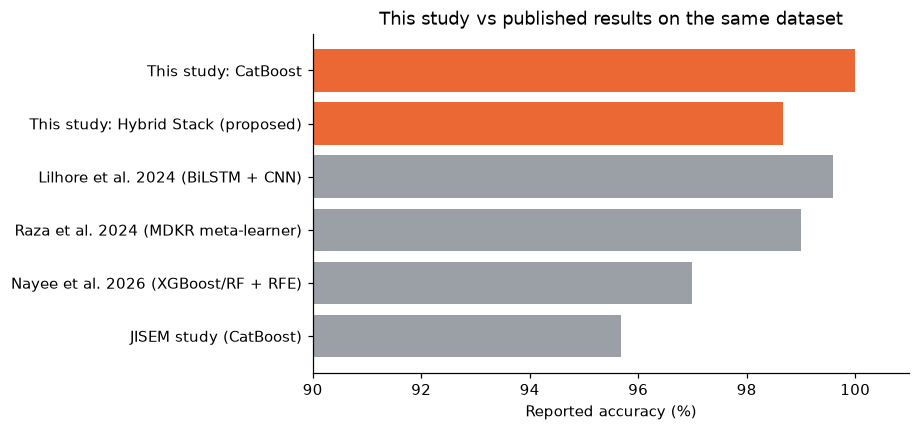

,study,accuracy_%
0,JISEM study (CatBoost),95.68
1,Nayee et al. 2026 (XGBoost/RF + RFE),96.99
2,Raza et al. 2024 (MDKR meta-learner),99.00
3,Lilhore et al. 2024 (BiLSTM + CNN),99.60
4,This study: Hybrid Stack (proposed),98.67
5,This study: CatBoost,100.00


In [57]:
# Task 56: Comparison with earlier papers on the same 1,503-row dataset
# Accuracies of the earlier papers are taken from their abstracts (see research/01_literature_review.md).
literature = pd.DataFrame([
    {"study": "JISEM study (CatBoost)", "accuracy_%": 95.68},
    {"study": "Nayee et al. 2026 (XGBoost/RF + RFE)", "accuracy_%": 96.99},
    {"study": "Raza et al. 2024 (MDKR meta-learner)", "accuracy_%": 99.0},
    {"study": "Lilhore et al. 2024 (BiLSTM + CNN)", "accuracy_%": 99.6},
    {"study": "This study: " + HYBRID, "accuracy_%": test_table.loc[HYBRID, "accuracy"]},
    {"study": "This study: CatBoost", "accuracy_%": test_table.loc["CatBoost", "accuracy"]},
])
literature.round(2).to_csv(RESULTS / "literature_comparison.csv", index=False)

colours = [ORANGE if "This study" in name else GREY for name in literature["study"]]
plt.barh(literature["study"], literature["accuracy_%"], color=colours)
plt.xlim(90, 101)
plt.xlabel("Reported accuracy (%)")
plt.title("This study vs published results on the same dataset")
plt.savefig(RESULTS / "fig22_literature_comparison.png")
plt.show()
literature.round(2)

In [58]:
# Task 57: One table with the headline numbers
summary = pd.Series({
    "Best model on the test set": test_table.index[0],
    "Hybrid Stack test accuracy (%)": round(test_table.loc[HYBRID, "accuracy"], 2),
    "Hybrid Stack 95% CI (%)": f"{ci_low:.2f}-{ci_high:.2f}",
    "Hybrid Stack F1 (%)": round(test_table.loc[HYBRID, "f1"], 2),
    "Hybrid Stack ROC-AUC": round(test_table.loc[HYBRID, "roc_auc"], 4),
    "Hybrid Stack 10-fold CV accuracy (%)": round(cv_scores[HYBRID].mean() * 100, 2),
    "Hybrid Stack grouped-CV accuracy (%)": round(robustness.loc[HYBRID, "grouped_cv_accuracy_%"], 2),
    "Top question (SHAP)": shap_importance.index[-1],
    "Top question (LIME)": lime_importance.index[-1],
    "SHAP-LIME global Spearman": round(global_spearman, 3),
    "Conformal coverage at 95% target (%)": round(conformal_table.loc[1, "actual_coverage_%"], 2),
}, name="value")
summary.to_csv(RESULTS / "final_summary.csv")
summary.to_frame()

,value
Best model on the test set,CatBoost
Hybrid Stack test accuracy (%),98.67
Hybrid Stack 95% CI (%),97.34-99.67
Hybrid Stack F1 (%),98.97
Hybrid Stack ROC-AUC,1.0
Hybrid Stack 10-fold CV accuracy (%),98.0
Hybrid Stack grouped-CV accuracy (%),83.63
Top question (SHAP),Feeling of guilt
Top question (LIME),Feeling of guilt
SHAP-LIME global Spearman,0.917
